# 6.5 Корреляция и причинность: код страницы

Аналитика 101 · блок «Дата аналитика» · тема 06 «Статистический вывод» · страница 6.5.

В ноутбуке шесть блоков кода со страницы: матрица корреляций, Пирсон против Спирмена, парадокс Симпсона и три нюанса. Между ними — квартет Энскомба из файла `anscombe.csv`. Данные учебные: клиенты из общего набора `data/clients/` и заказы со скидкой из `data/inference/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз. Блоки самостоятельны: каждый читает файлы заново.

Вывод получен на Python 3.13, NumPy 2.5, pandas 3.0 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файлы по пути от корня папки с материалами: `data/clients/clients.csv` и `data/inference/discounts.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка запоминает эту папку (в ней `anscombe.csv`), поднимается до папки, в которой есть `data/`, и делает её рабочей.

In [1]:
import os
import pathlib
import platform

import matplotlib
import numpy as np
import pandas as pd

here = pathlib.Path.cwd()                   # папка ноутбука: рядом лежит anscombe.csv
root = here
while not (root / "data" / "clients").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/clients/
assert (root / "data" / "clients" / "clients.csv").exists(), \
    "Не найдена папка data/clients/. Скачайте общий набор темы 04 и положите data/ рядом с папкой страницы"
assert (root / "data" / "inference" / "discounts.csv").exists(), \
    "Не найдена папка data/inference/. Скачайте общий набор темы 06 и положите его в ту же папку data/"
os.chdir(root)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.10.0


## Матрица корреляций

Блок печатает матрицу и сохраняет тепловую карту в файл `corr_heatmap.svg` в корне папки с материалами. Ячейка под ним показывает этот файл.

### Траты сильнее всего связаны с заказами, возраст — почти ни с чем

In [2]:
import matplotlib
import pandas as pd

matplotlib.use("Agg")                       # рисуем в файл, без окна
import matplotlib.pyplot as plt

df = pd.read_csv("data/clients/clients.csv").drop(columns="client_id")
corr = df.corr()                            # Пирсон для всех пар столбцов
print(corr.round(2), end="\n\n")

# одна пара с нуля: средний вклад (x − x̄)(y − ȳ), делённый на σx·σy
x, y = df["income"], df["spend"]
cov = ((x - x.mean()) * (y - y.mean())).sum() / (len(df) - 1)
print(f"ковариация = {cov:,.0f}".replace(",", " "))
print(f"r вручную = {cov / (x.std() * y.std()):.4f}, pandas = {x.corr(y):.4f}")

fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)   # 0 — белый, ±1 — насыщенный
ax.set_xticks(range(4), corr.columns)
ax.set_yticks(range(4), corr.columns)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
fig.savefig("corr_heatmap.svg", bbox_inches="tight")
print("тепловая карта сохранена: corr_heatmap.svg")

         age  income  orders  spend
age     1.00    0.15    0.08   0.04
income  0.15    1.00    0.42   0.50
orders  0.08    0.42    1.00   0.84
spend   0.04    0.50    0.84   1.00

ковариация = 139 563 886
r вручную = 0.5003, pandas = 0.5003
тепловая карта сохранена: corr_heatmap.svg


Карта под блоком нарисована SVG по этим же числам; файл corr_heatmap.svg, который сохраняет код, в страницу не вшит.

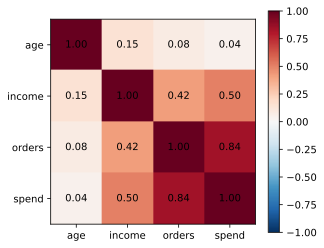

In [3]:
from IPython.display import SVG

SVG(filename="corr_heatmap.svg")

## Пирсон и Спирмен

### Один выброс переворачивает знак Пирсона, а Спирмен почти не меняется

In [4]:
import pandas as pd

df = pd.read_csv("data/clients/clients.csv").head(40)[["income", "spend"]]   # 40 учебных клиентов

def both(d):
    p = d["income"].corr(d["spend"])                       # Пирсон по значениям
    s = d["income"].corr(d["spend"], method="spearman")    # Спирмен по рангам
    return f"Пирсон {p:+.3f}   Спирмен {s:+.3f}"

print("40 клиентов:      ", both(df))

# один оптовый покупатель: доход 30 000 ₽, траты за квартал 1,5 млн ₽
wholesale = pd.DataFrame({"income": [30_000], "spend": [1_500_000]})
out = pd.concat([df, wholesale], ignore_index=True)
print("плюс один выброс: ", both(out))

# Спирмен — это Пирсон, посчитанный по рангам: у выброса ранг 41, а не 1,5 млн
ranks = out.rank()
print(ranks.tail(2))
print(f"Пирсон по рангам: {ranks['income'].corr(ranks['spend']):+.3f}")

# монотонная, но не линейная связь: Спирмен видит её целиком
x = pd.Series(range(1, 21))
y = 2.0 ** x
print(f"y = 2^x:          Пирсон {x.corr(y):+.3f}   Спирмен {x.corr(y, method='spearman'):+.3f}")

40 клиентов:       Пирсон +0.627   Спирмен +0.661
плюс один выброс:  Пирсон -0.152   Спирмен +0.573
    income  spend
39    25.5   22.0
40     6.5   41.0
Пирсон по рангам: +0.573
y = 2^x:          Пирсон +0.619   Спирмен +1.000


## Парадокс Симпсона

### По всем заказам скидка «поднимает» чек, внутри каждой категории — снижает

In [5]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/inference/discounts.csv")   # 120 учебных заказов со скидкой
print(df.head(3), end="\n\n")

def stats(g):
    slope = np.polyfit(g["discount"], g["check"], 1)[0]   # ₽ чека на 1 п. п. скидки
    return pd.Series({"заказов": len(g), "скидка": g["discount"].mean(), "чек": g["check"].mean(),
                      "r": g["discount"].corr(g["check"]), "наклон": slope})

table = df.groupby("category", sort=False).apply(stats, include_groups=False)
table.loc["все заказы"] = stats(df)
table = table.round({"скидка": 1, "чек": 0, "r": 2, "наклон": 0}).astype({"заказов": int, "чек": int, "наклон": int})
print(table)

   order_id category  discount  check
0         1   посуда         4   2470
1         2   посуда         3   2550
2         3   посуда         5   2280

            заказов  скидка   чек     r  наклон
category                                       
посуда           40     6.2  2204 -0.65     -48
текстиль         40    14.4  4660 -0.70    -108
свет             40    22.2  7006 -0.56    -131
все заказы      120    14.3  4623  0.73     198


## Квартет Энскомба

Четыре набора по 11 точек из статьи Энскомба 1973 года. Средние, дисперсии и корреляция у них почти одинаковые, а графики разные: прямая с шумом, дуга, прямая с одним выбросом и столбик точек с одной далёкой. Этой ячейки на странице нет: там квартет показан в анимации.

In [6]:
q = pd.read_csv(here / "anscombe.csv")
for name, g in q.groupby("set"):
    print(f"набор {name}: среднее x = {g.x.mean():.2f}, y = {g.y.mean():.2f}; дисперсия x = {g.x.var():.2f}, y = {g.y.var():.2f}; "
          f"r = {g.x.corr(g.y):.3f}, Спирмен = {g.x.corr(g.y, method='spearman'):.3f}")

набор I: среднее x = 9.00, y = 7.50; дисперсия x = 11.00, y = 4.13; r = 0.816, Спирмен = 0.818
набор II: среднее x = 9.00, y = 7.50; дисперсия x = 11.00, y = 4.13; r = 0.816, Спирмен = 0.691
набор III: среднее x = 9.00, y = 7.50; дисперсия x = 11.00, y = 4.12; r = 0.816, Спирмен = 0.991
набор IV: среднее x = 9.00, y = 7.50; дисперсия x = 11.00, y = 4.12; r = 0.817, Спирмен = 0.500


## Три нюанса

### Связь сильная, а r = 0: дугу Пирсон не видит

In [7]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(6521)
push = rng.integers(0, 7, 300)                     # пушей в неделю у 300 учебных пользователей
days = 20 - 1.5 * (push - 3) ** 2 + rng.normal(0, 2, 300)   # активных дней за месяц
df = pd.DataFrame({"push": push, "days": days.clip(0, 30).round()})

print(f"Пирсон {df['push'].corr(df['days']):+.3f}   Спирмен {df['push'].corr(df['days'], method='spearman'):+.3f}")
print(df.groupby("push")["days"].mean().round(1).to_string())
print(f"Пирсон для (push − 3)² и дней: {((df['push'] - 3) ** 2).corr(df['days']):+.3f}")

Пирсон +0.001   Спирмен -0.062
push
0     6.3
1    13.9
2    18.7
3    19.7
4    18.7
5    13.9
6     6.7
Пирсон для (push − 3)² и дней: -0.937


### Те же клиенты, усреднённые по возрасту, дают r в шесть раз больше

In [8]:
import pandas as pd

df = pd.read_csv("data/clients/clients.csv")   # 1 000 учебных клиентов

by_age = df.groupby("age", as_index=False)["income"].mean()           # 53 точки: средний доход по возрасту
by_dec = df.groupby(df["age"] // 10 * 10)[["age", "income"]].mean()   # 7 точек: по десятилетиям

print(f"по клиентам:       r = {df['age'].corr(df['income']):.2f}  ({len(df)} точек)")
print(f"по годам возраста: r = {by_age['age'].corr(by_age['income']):.2f}  ({len(by_age)} точки)")
print(f"по десятилетиям:   r = {by_dec['age'].corr(by_dec['income']):.2f}  ({len(by_dec)} точек)")

по клиентам:       r = 0.15  (1000 точек)
по годам возраста: r = 0.62  (53 точки)
по десятилетиям:   r = 0.94  (7 точек)


### Два независимых ряда с трендом дают r = 0,9, а их изменения — ноль

In [9]:
import numpy as np

rng = np.random.default_rng(6522)
t = np.arange(365)
orders = 200 + 0.3 * t + rng.normal(0, 12, 365)       # заказы учебного магазина в день
subs = 9_000 + 15 * t + rng.normal(0, 400, 365)       # подписчики чужого канала: никак не связаны
print(f"уровни:    r = {np.corrcoef(orders, subs)[0, 1]:.2f}")
print(f"изменения: r = {np.corrcoef(np.diff(orders), np.diff(subs))[0, 1]:+.2f}")

# 1 000 пар независимых случайных блужданий по 365 дней
walks = rng.normal(size=(1000, 2, 365)).cumsum(axis=2)
r = np.array([np.corrcoef(a, b)[0, 1] for a, b in walks])
rd = np.array([np.corrcoef(np.diff(a), np.diff(b))[0, 1] for a, b in walks])
print(f"блуждания: |r| > 0,5 у {np.mean(np.abs(r) > 0.5):.0%} пар, медиана |r| = {np.median(np.abs(r)):.2f}")
print(f"их изменения: |r| > 0,5 у {np.mean(np.abs(rd) > 0.5):.0%} пар, медиана |r| = {np.median(np.abs(rd)):.2f}")

уровни:    r = 0.90
изменения: r = -0.05


блуждания: |r| > 0,5 у 41% пар, медиана |r| = 0.42
их изменения: |r| > 0,5 у 0% пар, медиана |r| = 0.04
